# F1 Podium Prediction — Milestone 1

> **Generated file: do not edit this notebook by hand.** The source of truth is
> `scripts/build_notebook.py`. Edit the cells there, then rebuild and re-execute the notebook
> (see that script's docstring). Hand edits to this `.ipynb` are overwritten on the next build.

Goal: for each driver in each race, predict whether they finish on the podium
(`results.positionOrder <= 3`), using only information available after qualifying.

Sections: **1** Setup, **2** Data Loading, **3** Raw Data Audit, **4** Audit follow-ups,
**5** Findings → open decisions, **6** Cleaning. Sections 3–4 only *measure* the raw data;
cleaning happens only in section 6, following decisions recorded in the notebook.
Reusable code lives in `src/f1podium/`.

## 1. Setup

Make the `src/` folder importable. We search upwards from the current folder so the
same cell works when run from `notebooks/`, from the repo root, or on Kaggle
(where `src/` must be provided alongside the notebook).

In [1]:
import sys
from pathlib import Path

def _add_src_to_path() -> Path:
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "src" / "f1podium").is_dir():
            src = base / "src"
            if str(src) not in sys.path:
                sys.path.insert(0, str(src))
            return src
    raise FileNotFoundError("Could not find src/f1podium above " + str(Path.cwd()))

SRC_DIR = _add_src_to_path()

%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
from IPython.display import display

from f1podium import config
from f1podium.clean import (
    INDY500_CIRCUIT_REF,
    INDY500_YEARS,
    NON_START_STATUSES,
    STEP_NON_STARTER,
    WITHDREW_STATUS,
    exclude_indy500,
    filter_non_starters,
    resolve_duplicate_results,
)
from f1podium.load import load_all
from f1podium.validate import (
    find_duplicates,
    missing_summary,
    run_foreign_key_checks,
    run_primary_key_checks,
)

pd.set_option("display.max_rows", 250)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

np.random.seed(config.RANDOM_SEED)

print("Python     :", sys.version.split()[0], "|", sys.executable)
print("pandas     :", pd.__version__)
print("src        :", SRC_DIR)
print("raw data   :", config.RAW_DIR)
print("split      : train <=", config.TRAIN_END_YEAR, "| val", config.VAL_YEARS,
      "| test >=", config.TEST_START_YEAR)
print("seed       :", config.RANDOM_SEED)

Python     : 3.13.7 | C:\Users\yshim\dev\f1-podium\.venv\Scripts\python.exe
pandas     : 3.0.6
src        : C:\Users\yshim\dev\f1-podium\src
raw data   : C:\Users\yshim\dev\f1-podium\data\raw
split      : train <= 2019 | val (2020, 2021) | test >= 2022
seed       : 42


## 2. Data Loading

`load_all()` reads the 14 CSVs with an explicit schema per table:
`\N` (and empty fields) become missing; IDs/counts use nullable `Int64`;
text uses `string`; dates are parsed strictly with `%Y-%m-%d`.
The loader raises if a file's columns differ from the declared schema.

In [3]:
tables = load_all()

load_summary = pd.DataFrame(
    {
        "rows": {n: len(df) for n, df in tables.items()},
        "columns": {n: df.shape[1] for n, df in tables.items()},
        "memory_MB": {n: round(df.memory_usage(deep=True).sum() / 1e6, 2) for n, df in tables.items()},
    }
).rename_axis("table")
display(load_summary)

,rows,columns,memory_MB
table,,,
circuits,77,9,0.03
constructor_results,12625,5,1.15
constructor_standings,13391,7,1.38
constructors,212,5,0.06
driver_standings,34863,7,3.62
drivers,861,9,0.34
lap_times,589081,6,60.09
pit_stops,11371,7,1.79
qualifying,10494,9,2.35


Declared dtypes of the three tables we will use most:

In [4]:
for name in ["races", "results", "qualifying"]:
    print(f"--- {name}")
    print(tables[name].dtypes.to_string(), end="\n\n")

--- races
raceId                  Int64
year                    Int64
round                   Int64
circuitId               Int64
name                   string
date           datetime64[us]
time                   string
url                    string
fp1_date       datetime64[us]
fp1_time               string
fp2_date       datetime64[us]
fp2_time               string
fp3_date       datetime64[us]
fp3_time               string
quali_date     datetime64[us]
quali_time             string
sprint_date    datetime64[us]
sprint_time            string

--- results
resultId             Int64
raceId               Int64
driverId             Int64
constructorId        Int64
number               Int64
grid                 Int64
position             Int64
positionText        string
positionOrder        Int64
points             float64
laps                 Int64
time                string
milliseconds         Int64
fastestLap           Int64
rank                 Int64
fastestLapTime      string
faste

In [5]:
# Short aliases used throughout the audit
races = tables["races"]
results = tables["results"]
qualifying = tables["qualifying"]

def with_year(df: pd.DataFrame) -> pd.DataFrame:
    """Attach races.year, checking the join neither drops nor duplicates rows."""
    out = df.merge(races[["raceId", "year"]], on="raceId", how="left", validate="many_to_one")
    assert len(out) == len(df), "join changed the row count"
    assert out["year"].notna().all(), "some rows have a raceId not in races"
    return out

## 3. Raw Data Audit

### 3.1 Missing values per column

Count and percentage of missing values for every column of every table
(after treating `\N` and empty fields as missing).

In [6]:
missing = missing_summary(tables)
display(missing.sort_values(["table", "pct_missing"], ascending=[True, False]).reset_index(drop=True))

,table,column,dtype,n_rows,n_missing,pct_missing
0,circuits,circuitId,Int64,77,0,0.00
1,circuits,circuitRef,string,77,0,0.00
2,circuits,name,string,77,0,0.00
3,circuits,location,string,77,0,0.00
4,circuits,country,string,77,0,0.00
5,circuits,lat,float64,77,0,0.00
6,circuits,lng,float64,77,0,0.00
7,circuits,alt,Int64,77,0,0.00
8,circuits,url,string,77,0,0.00
9,constructor_results,status,string,12625,12608,99.87


Only the columns that have at least one missing value, worst first:

In [7]:
display(
    missing[missing["n_missing"] > 0]
    .sort_values("pct_missing", ascending=False)
    .reset_index(drop=True)
)

,table,column,dtype,n_rows,n_missing,pct_missing
0,constructor_results,status,string,12625,12608,99.87
1,races,sprint_time,string,1125,1110,98.67
2,races,sprint_date,datetime64[us],1125,1107,98.40
3,races,fp3_time,string,1125,1072,95.29
4,races,fp1_time,string,1125,1057,93.96
5,races,fp2_time,string,1125,1057,93.96
6,races,quali_time,string,1125,1057,93.96
7,races,fp3_date,datetime64[us],1125,1053,93.60
8,drivers,number,Int64,861,802,93.15
9,races,fp1_date,datetime64[us],1125,1035,92.00


### 3.2 Primary keys

A key passes if it has no nulls and no repeated values. Surrogate ids (e.g. `raceId`)
are listed first, then natural/composite keys, which say more about the data.
`results (raceId, driverId)` is **expected to fail**: early seasons have shared drives.

In [8]:
pk_results = run_primary_key_checks(tables)
display(pk_results)
print(f"{(~pk_results['passed']).sum()} of {len(pk_results)} primary-key checks failed")

,table,key,n_rows,n_null_key,n_duplicate_rows,passed
0,circuits,circuitId,77,0,0,True
1,constructors,constructorId,212,0,0,True
2,drivers,driverId,861,0,0,True
3,races,raceId,1125,0,0,True
4,status,statusId,139,0,0,True
5,seasons,year,75,0,0,True
6,results,resultId,26759,0,0,True
7,sprint_results,resultId,360,0,0,True
8,qualifying,qualifyId,10494,0,0,True
9,driver_standings,driverStandingsId,34863,0,0,True


1 of 24 primary-key checks failed


### 3.3 Foreign keys

For each relationship: how many child rows have a null key, and how many point to an
id that does not exist in the parent table.

In [9]:
fk_results = run_foreign_key_checks(tables)
display(fk_results)
print(f"{(~fk_results['passed']).sum()} of {len(fk_results)} foreign-key checks failed")

,child,fk,parent,n_child_rows,n_null_fk,n_unmatched_rows,n_unmatched_distinct,example_unmatched,passed
0,races,circuitId,circuits.circuitId,1125,0,0,0,[],True
1,races,year,seasons.year,1125,0,0,0,[],True
2,results,raceId,races.raceId,26759,0,0,0,[],True
3,results,driverId,drivers.driverId,26759,0,0,0,[],True
4,results,constructorId,constructors.constructorId,26759,0,0,0,[],True
5,sprint_results,raceId,races.raceId,360,0,0,0,[],True
6,sprint_results,driverId,drivers.driverId,360,0,0,0,[],True
7,sprint_results,constructorId,constructors.constructorId,360,0,0,0,[],True
8,qualifying,raceId,races.raceId,10494,0,0,0,[],True
9,qualifying,driverId,drivers.driverId,10494,0,0,0,[],True


0 of 23 foreign-key checks failed


### 3.4 Duplicate `(raceId, driverId)` rows in `results`, by year

Our modelling grain is one row per `(raceId, driverId)`. Here we count, per season,
the rows that violate it. Nothing is dropped; the rule for handling them is an open decision.

In [10]:
dups = with_year(find_duplicates(results, ["raceId", "driverId"]))

dup_by_year = pd.DataFrame({
    "n_duplicated_pairs": dups.drop_duplicates(["raceId", "driverId"]).groupby("year").size(),
    "n_rows_involved": dups.groupby("year").size(),
    "n_races_affected": dups.groupby("year")["raceId"].nunique(),
})
dup_by_year.loc["Total"] = dup_by_year.sum()
display(dup_by_year)

,n_duplicated_pairs,n_rows_involved,n_races_affected
year,,,
1950,4,8,3
1951,4,8,2
1952,3,6,3
1953,14,30,5
1954,16,33,5
1955,15,33,4
1956,12,24,6
1957,8,16,5
1958,3,6,3


Example duplicated entries (same driver, same race, more than one row):

In [11]:
example = dups.merge(
    tables["drivers"][["driverId", "driverRef"]], on="driverId", how="left", validate="many_to_one"
).merge(
    tables["constructors"][["constructorId", "constructorRef"]], on="constructorId", how="left", validate="many_to_one"
)
display(example[[
    "year", "raceId", "driverId", "driverRef", "constructorRef", "number",
    "grid", "positionText", "positionOrder", "points", "laps", "statusId",
]].head(12))

,year,raceId,driverId,driverRef,constructorRef,number,grid,positionText,positionOrder,points,laps,statusId
0,1978,540,229,ertl,ats,10,0,F,26,0.0,0,81
1,1978,540,229,ertl,ensign,23,0,F,29,0.0,0,97
2,1964,717,373,clark,lotus-climax,1,1,7,7,0.0,102,60
3,1964,717,373,clark,lotus-climax,2,1,R,12,0.0,54,98
4,1962,733,465,greene,lotus-climax,48,0,W,22,0.0,0,54
5,1962,733,465,greene,gilby,50,0,W,25,0.0,0,54
6,1961,742,475,moss,ferguson,26,20,D,19,0.0,56,2
7,1961,742,475,moss,lotus-climax,28,5,R,21,0.0,44,23
8,1961,745,418,gregory,lotus-climax,22,11,R,17,0.0,23,6
9,1961,745,418,gregory,lotus-climax,21,15,11,11,0.0,92,18


### 3.5 Qualifying data: first year and coverage per season

Two coverage measures per season:

- **races covered**: share of races with *any* qualifying rows;
- **entries covered**: share of `results` rows (driver–race entries) whose
  `(raceId, driverId)` also appears in `qualifying`. This is what matters for our grain:
  it is the share of model rows that would have qualifying features.

In [12]:
quali_race_ids = set(qualifying["raceId"].dropna())
first_quali_year = int(races.loc[races["raceId"].isin(quali_race_ids), "year"].min())
print("First season with qualifying data:", first_quali_year)

quali_pairs = qualifying[["raceId", "driverId"]].drop_duplicates().assign(has_quali=True)
entries = with_year(results[["raceId", "driverId"]]).merge(
    quali_pairs, on=["raceId", "driverId"], how="left", validate="many_to_one"
)
assert len(entries) == len(results), "join changed the row count"
entries["has_quali"] = entries["has_quali"].fillna(False).astype(bool)

races_with_results = set(results["raceId"])
season = races.assign(
    has_results=races["raceId"].isin(races_with_results),
    has_quali=races["raceId"].isin(quali_race_ids),
)
quali_cov = pd.DataFrame({
    "n_races": season.groupby("year").size(),
    "n_races_with_results": season.groupby("year")["has_results"].sum(),
    "n_races_with_quali": season.groupby("year")["has_quali"].sum(),
    "n_results_rows": entries.groupby("year").size(),
    "n_results_rows_with_quali": entries.groupby("year")["has_quali"].sum(),
}).fillna(0).astype(int)
quali_cov["pct_races_covered"] = (100 * quali_cov["n_races_with_quali"] / quali_cov["n_races"]).round(1)
quali_cov["pct_entries_covered"] = (
    100 * quali_cov["n_results_rows_with_quali"] / quali_cov["n_results_rows"].replace(0, np.nan)
).round(1)
display(quali_cov)

First season with qualifying data: 1994


,n_races,n_races_with_results,n_races_with_quali,n_results_rows,n_results_rows_with_quali,pct_races_covered,pct_entries_covered
year,,,,,,,
1950,7,7,0,160,0,0.0,0.0
1951,8,8,0,179,0,0.0,0.0
1952,8,8,0,215,0,0.0,0.0
1953,9,9,0,246,0,0.0,0.0
1954,9,9,0,230,0,0.0,0.0
1955,7,7,0,180,0,0.0,0.0
1956,8,8,0,190,0,0.0,0.0
1957,8,8,0,171,0,0.0,0.0
1958,11,11,0,241,0,0.0,0.0


### 3.6 `grid = 0` by decade

`grid = 0` has no single documented meaning (e.g. pit-lane start vs. did not start).
We only count it here; how to treat it is an open decision.

In [13]:
grid = with_year(results[["raceId", "grid"]])
grid["decade"] = (grid["year"] // 10 * 10).astype(int)
grid_by_decade = grid.groupby("decade").agg(
    n_results_rows=("grid", "size"),
    n_grid_null=("grid", lambda s: int(s.isna().sum())),
    n_grid_zero=("grid", lambda s: int((s == 0).sum())),
)
grid_by_decade["pct_grid_zero"] = (100 * grid_by_decade["n_grid_zero"] / grid_by_decade["n_results_rows"]).round(2)
display(grid_by_decade)

,n_results_rows,n_grid_null,n_grid_zero,pct_grid_zero
decade,,,,
1950,2007,0,68,3.39
1960,2113,0,198,9.37
1970,3807,0,351,9.22
1980,4503,0,571,12.68
1990,4250,0,357,8.4
2000,3643,0,8,0.22
2010,4297,0,28,0.65
2020,2139,0,57,2.66


## 4. Audit follow-ups

Deeper looks at the three open questions raised by the audit. **Investigation only:**
nothing is cleaned, dropped or recoded in the data; any grouping below exists only to
make a table readable.

### 4.1 What do `grid = 0` rows look like?

Two cross-tabs of the `grid = 0` rows from `results`, by decade:

- **× status**: the race outcome recorded in `status` (e.g. *Did not qualify*, *Engine*, *Finished*).
- **× positionText**: Ergast's result code. Letters are non-classifications
  (`R` retired, `D` disqualified, `E` excluded, `W` withdrawn, `F` failed to qualify,
  `N` not classified). Numbers are classified finishing positions; to keep the table
  narrow they are grouped into *classified P1–3* and *classified P4+*.

If `grid = 0` mostly means "never started", we expect it to sit with *Did not qualify* /
`F` / `W`. If it means "started from the pit lane", we expect normal outcomes
(finishes, retirements).

In [14]:
POS_TEXT_LABELS = {
    "R": "R (retired)",
    "D": "D (disqualified)",
    "E": "E (excluded)",
    "W": "W (withdrawn)",
    "F": "F (failed to qualify)",
    "N": "N (not classified)",
}

def position_text_group(pt: str) -> str:
    """Readable group for a positionText value (display only)."""
    if pt.isdigit():
        return "classified P1-3" if int(pt) <= 3 else "classified P4+"
    return POS_TEXT_LABELS.get(pt, pt)

grid0 = with_year(results.loc[results["grid"] == 0, ["raceId", "statusId", "positionText"]])
grid0["decade"] = (grid0["year"] // 10 * 10).astype(int)
grid0 = grid0.merge(tables["status"], on="statusId", how="left", validate="many_to_one")
assert grid0["status"].notna().all(), "grid = 0 row with unknown statusId"
grid0["positionText_group"] = grid0["positionText"].map(position_text_group)
print("grid = 0 rows:", len(grid0))

def crosstab_by_decade(row_col: str, top_n: int | None = None) -> pd.DataFrame:
    """Rows sorted by total; optionally keep the top_n rows and fold the rest into 'Other'."""
    ct = pd.crosstab(grid0[row_col], grid0["decade"], margins=True, margins_name="Total")
    body = ct.drop(index="Total").sort_values("Total", ascending=False)
    if top_n is not None and len(body) > top_n:
        rest = body.iloc[top_n:]
        other = rest.sum().rename(f"Other ({len(rest)} statuses)")
        body = pd.concat([body.iloc[:top_n], other.to_frame().T])
    return pd.concat([body, ct.loc[["Total"]]])

grid = 0 rows: 1638


**`grid = 0` × status**: the top 15 statuses, with the rest folded into *Other*. The last row is the column total:

In [15]:
display(crosstab_by_decade("status", top_n=15))

decade,1950,1960,1970,1980,1990,2000,2010,2020,Total
Did not qualify,49,71,298,380,209,2,4,0,1013
Did not prequalify,0,3,32,164,132,0,0,0,331
Withdrew,13,118,14,10,4,1,2,2,164
+1 Lap,0,0,0,0,0,0,5,22,27
Finished,0,0,0,0,0,0,3,19,22
Accident,2,3,6,4,3,0,1,1,20
Injury,0,1,0,1,4,1,1,0,8
+2 Laps,0,0,0,0,0,0,4,3,7
Excluded,0,0,0,5,1,0,0,0,6
Engine,4,1,0,0,0,0,0,1,6


**`grid = 0` × positionText group:**

In [16]:
display(crosstab_by_decade("positionText_group"))

decade,1950,1960,1970,1980,1990,2000,2010,2020,Total
positionText_group,,,,,,,,,
F (failed to qualify),49,74,330,544,342,5,4,0,1348
W (withdrawn),19,124,21,17,11,3,4,4,203
classified P4+,0,0,0,0,0,0,13,47,60
R (retired),0,0,0,1,0,0,7,6,14
E (excluded),0,0,0,5,2,0,0,0,7
D (disqualified),0,0,0,4,2,0,0,0,6
Total,68,198,351,571,357,8,28,57,1638


**What this shows.**

- **Before 2000, `grid = 0` almost always means "did not start".** Of the 1,638 rows,
  1,348 are `F` (failed to qualify): 1,013 *Did not qualify* plus 331 *Did not prequalify*.
  Another 203 are `W` (withdrawn). These cars never took the start. Prequalifying shows up only
  in the 1970s–90s, when more cars entered than could race.
- **From the 2010s on, it mostly means "started from the pit lane".** The statuses become
  *Finished*, *+1 Lap* and mechanical retirements, so these cars raced. All 60 classified
  `grid = 0` rows fall in 2015–2024, and the best finish is **P5**. No `grid = 0` entry in this
  dataset reached the podium.
- **Some rows are still unexplained (Unknown).** 18 *Accident* rows from the 1950s–1990s have
  `grid = 0`. These may be accidents in practice or qualifying; the cause is not investigated here.
- **Leakage note.** `status` and `positionText` are post-race columns, so they cannot be model
  features. They are used here only to understand what `grid = 0` means. Failing to qualify is
  known *after qualifying*, which is our prediction cutoff, so deciding how to treat those rows
  remains an open decision rather than a leakage problem.

#### 4.1b Non-start statuses: `grid = 0` vs `grid > 0`

The other direction: start from statuses that *sound* like a non-start and check their grid value.
`laps_gt0` counts rows that completed at least one lap, which is direct evidence that the car raced.

The candidate list is for investigation only; it is **not** a non-starter definition. It includes
*Not classified* to test it. In F1 terminology, *not classified* means the car started but covered
too little of the race distance to be classified. `laps` is a post-race column, used here as evidence only.

In [17]:
NON_START_CANDIDATES = [
    "Did not qualify", "Did not prequalify", "107% Rule", "Withdrew", "Not classified",
    "Excluded", "Injury", "Injured", "Driver unwell", "Safety concerns", "Underweight",
]
missing_statuses = set(NON_START_CANDIDATES) - set(tables["status"]["status"])
assert not missing_statuses, f"not in status table: {missing_statuses}"

cand = (
    results[["raceId", "statusId", "grid", "laps"]]
    .merge(tables["status"], on="statusId", how="left", validate="many_to_one")
    .query("status in @NON_START_CANDIDATES")
)
cand["grid_group"] = np.where(cand["grid"] > 0, "grid>0", "grid=0")
non_start_split = (
    cand.groupby(["status", "grid_group"])
    .agg(rows=("laps", "size"), laps_gt0=("laps", lambda s: int((s > 0).sum())))
    .unstack("grid_group", fill_value=0)
    .reindex(NON_START_CANDIDATES)
    .fillna(0)
    .astype(int)
)
non_start_split.columns = [f"{grid}: {measure}" for measure, grid in non_start_split.columns]
non_start_split = non_start_split[["grid=0: rows", "grid=0: laps_gt0", "grid>0: rows", "grid>0: laps_gt0"]]
display(non_start_split)

,grid=0: rows,grid=0: laps_gt0,grid>0: rows,grid>0: laps_gt0
status,,,,
Did not qualify,1013,0,12,1
Did not prequalify,331,0,0,0
107% Rule,2,0,7,0
Withdrew,164,0,84,23
Not classified,0,0,172,172
Excluded,6,0,2,1
Injury,8,0,5,1
Injured,2,0,5,0
Driver unwell,0,0,10,9


Where the `Withdrew` rows with `grid > 0` come from (the top 5 races):

In [18]:
withdrew_started_grid = with_year(
    results.loc[(results["statusId"].isin(tables["status"].query("status == 'Withdrew'")["statusId"]))
                & (results["grid"] > 0), ["raceId", "laps"]]
).merge(races[["raceId", "name"]], on="raceId", how="left", validate="many_to_one")
display(
    withdrew_started_grid.groupby(["year", "name"])
    .agg(rows=("laps", "size"), laps_gt0=("laps", lambda s: int((s > 0).sum())))
    .sort_values("rows", ascending=False)
    .head(5)
)

,,rows,laps_gt0
year,name,,
2005,United States Grand Prix,14,0
1976,Japanese Grand Prix,4,4
1975,Spanish Grand Prix,3,2
1954,Argentine Grand Prix,2,0
1952,Swiss Grand Prix,2,2


**What this shows.**

- **Most non-start statuses go with `grid = 0`, but not all of them.** *Did not prequalify* is 331 rows, all with
  `grid = 0`. *Did not qualify* has 1,013 rows with `grid = 0` and 12 with `grid > 0`; one of those 12 even
  completed a lap.
- **`Withdrew` covers three different situations:**
  - 164 rows with `grid = 0`: never took a grid slot.
  - 61 rows with `grid > 0` and no laps: qualified, then did not start. 14 of these are the
    2005 US GP, where most of the field withdrew after the formation lap.
  - 23 rows with `grid > 0` and at least one lap: started the race, then withdrew.
- **`Not classified` is not a non-start.** All 172 rows have `grid > 0` and at least one lap.
- **Other candidates are small and mixed.**
  - *107% Rule:* 7 of its 9 rows have `grid > 0`, but none completed a lap.
  - *Driver unwell:* 9 of its 10 rows completed laps, so it mostly means "started, then stopped".
  - *Excluded* and *Injury:* no `grid = 0` row completed a lap, but one `grid > 0` row each did.
- **So neither signal is enough on its own.** `grid = 0` alone and status alone each misclassify
  some entries. Any non-starter definition has to say which signals it uses, and whether those
  signals are known at the prediction cutoff.

### 4.2 The 85 duplicate `(raceId, driverId)` pairs

One row per duplicated pair, describing its rows:

- `n_rows`: how many `results` rows the driver has in that race;
- `n_rows_grid_pos`: how many of those rows have `grid > 0` (i.e. a real starting slot);
- `positionTexts`: each row's `positionText`, in `positionOrder` order;
- `constructors_differ`: whether the rows are for different constructors.

Then the pairs are summarised as **counts per pattern**. For the pattern,
`positionText` is reduced to *classified* vs. its letter code, so that e.g. `4 / R` and
`7 / R` count as the same pattern (`R + classified`).

In [19]:
dup_rows = (
    with_year(find_duplicates(results, ["raceId", "driverId"]))
    .merge(tables["drivers"][["driverId", "driverRef"]], on="driverId", how="left", validate="many_to_one")
    .sort_values(["year", "raceId", "driverId", "positionOrder"])
)
dup_rows["pt_kind"] = dup_rows["positionText"].map(lambda pt: "classified" if pt.isdigit() else pt)

dup_pairs = (
    dup_rows.groupby(["raceId", "driverId"], sort=False)
    .agg(
        year=("year", "first"),
        driverRef=("driverRef", "first"),
        n_rows=("resultId", "size"),
        n_rows_grid_pos=("grid", lambda s: int((s > 0).sum())),
        positionTexts=("positionText", lambda s: " / ".join(s)),
        n_constructors=("constructorId", "nunique"),
        result_pattern=("pt_kind", lambda s: " + ".join(sorted(s))),
    )
    .reset_index()
)
dup_pairs["constructors_differ"] = dup_pairs["n_constructors"] > 1
indy_race_ids = set(races.loc[races["name"] == "Indianapolis 500", "raceId"])
dup_pairs["indy500"] = dup_pairs["raceId"].isin(indy_race_ids)
assert len(dup_pairs) == dup_rows[["raceId", "driverId"]].drop_duplicates().shape[0]
print("duplicated pairs:", len(dup_pairs), "| rows involved:", len(dup_rows),
      "| pairs from the Indianapolis 500:", int(dup_pairs["indy500"].sum()))
display(dup_pairs[[
    "year", "raceId", "driverRef", "n_rows", "n_rows_grid_pos",
    "positionTexts", "constructors_differ", "indy500",
]])

duplicated pairs: 85 | rows involved: 176 | pairs from the Indianapolis 500: 21


,year,raceId,driverRef,n_rows,n_rows_grid_pos,positionTexts,constructors_differ,indy500
0,1950,835,bettenhausen,2,2,5 / R,True,True
1,1950,838,rosier,2,2,6 / R,False,False
2,1950,839,fangio,2,2,R / R,False,False
3,1950,839,ascari,2,2,2 / R,False,False
4,1951,828,fangio,2,2,1 / 11,False,False
5,1951,828,ascari,2,2,2 / R,False,False
6,1951,828,fagioli,2,2,1 / 11,False,False
7,1951,831,farina,2,2,3 / R,False,False
8,1952,817,farina,2,2,R / R,False,False
9,1952,820,schell,2,2,R / R,False,False


**Counts per pattern** (`years` = first–last season the pattern occurs):

In [20]:
dup_patterns = (
    dup_pairs.groupby(["n_rows", "n_rows_grid_pos", "constructors_differ", "result_pattern"])
    .agg(
        n_pairs=("year", "size"),
        n_indy500=("indy500", "sum"),
        years=("year", lambda y: f"{y.min()}-{y.max()}"),
    )
    .reset_index()
    .sort_values("n_pairs", ascending=False, ignore_index=True)
)
assert dup_patterns["n_pairs"].sum() == len(dup_pairs)
display(dup_patterns)

,n_rows,n_rows_grid_pos,constructors_differ,result_pattern,n_pairs,n_indy500,years
0,2,2,False,R + classified,46,7,1950-1964
1,2,2,False,R + R,12,1,1950-1958
2,2,2,False,classified + classified,8,2,1951-1956
3,2,2,True,R + classified,7,6,1950-1956
4,3,3,True,R + R + classified,3,3,1953-1954
5,3,3,False,R + classified + classified,2,0,1955-1955
6,2,0,True,F + F,2,0,1958-1978
7,2,2,True,R + R,2,2,1953-1954
8,2,0,True,W + W,1,0,1962-1962
9,2,2,True,D + R,1,0,1961-1961


**What this shows.**

- **Each row is one car the driver drove, and it carries that car's grid slot and result.**
  This was confirmed on the 1951 French GP (raceId 828). Fangio has one row for car 8, grid 7,
  **1st**: Fagioli's car, which Fangio took over and won in. He has a second row for his own
  car 24, grid 1, 11th. Fagioli has rows for the same two cars. So in shared drives, `grid`
  describes the *car*, not where that driver started.
- **Most duplicates are classic 1950s shared drives.** 82 of the 85 pairs have `grid > 0` in every
  row. The most common pattern is *R + classified* with the same constructor (46 pairs): the
  driver's own car retired, and they finished the race in a teammate's car. In 8 pairs, both
  cars the driver drove were classified.
- **3 pairs are not shared drives.** They have `grid = 0` in both rows: *F + F* in 1958 and 1978,
  and *W + W* in 1962. The driver was entered in two cars and started neither. These overlap
  with the non-starter question in 4.1.
- **21 of the 85 pairs come from the Indianapolis 500** (1950, 1953, 1954). In about half of them
  (11 of 21) the constructors differ, because drivers relieved each other across teams. This links the shared-drive
  rule to the open Indy 500 exclusion decision.
- **Why it matters for the target.** With shared drives, one driver can have both a podium row
  and a non-podium row in the same race (Fangio 1951 above). Any rule for these rows has to say
  what `podium` means for such a driver. That is an open decision and is not settled here.

### 4.3 Qualifying coverage per season, 1990–2024

Share of race entries (`results` rows) that have a matching `qualifying` row: the
`pct_entries_covered` column from 3.5, plotted. Dashed lines mark the planned
train / validation / test boundaries. (Race-level coverage is almost identical and is
in the 3.5 table.)

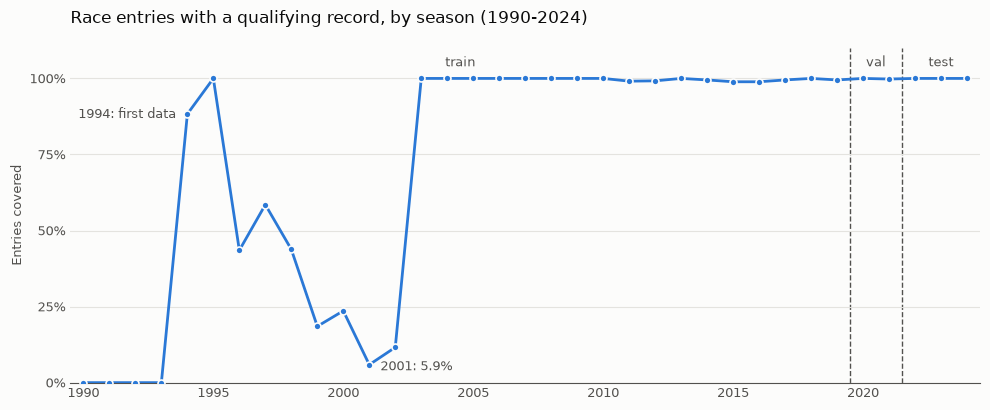

In [21]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

INK, INK_MUTED, SERIES, SURFACE = "#0b0b0b", "#52514e", "#2a78d6", "#fcfcfb"

cov = quali_cov.loc[1990:2024, "pct_entries_covered"]
years, pct = cov.index.astype(int), cov.astype(float).to_numpy()

fig, ax = plt.subplots(figsize=(10, 4.2), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.plot(years, pct, color=SERIES, linewidth=2, marker="o", markersize=5,
        markeredgecolor=SURFACE, markeredgewidth=1.2, zorder=3)

# Planned split boundaries
for x in (config.TRAIN_END_YEAR + 0.5, config.TEST_START_YEAR - 0.5):
    ax.axvline(x, color=INK_MUTED, linewidth=1, linestyle="--", zorder=1)
for x, label in [((1990 + config.TRAIN_END_YEAR) / 2, "train"),
                 (sum(config.VAL_YEARS) / 2, "val"),
                 ((config.TEST_START_YEAR + 2024) / 2, "test")]:
    ax.text(x, 103, label, ha="center", va="bottom", color=INK_MUTED, fontsize=9)

# Selective direct labels: first year with data and the lowest season after it
first = int(years[pct > 0][0])
gap_years = cov.loc[first:2002]
low = int(gap_years.idxmin())
ax.annotate(f"{first}: first data", (first, cov[first]), xytext=(-8, 0),
            textcoords="offset points", ha="right", va="center", color=INK_MUTED, fontsize=9)
ax.annotate(f"{low}: {cov[low]:.1f}%", (low, cov[low]), xytext=(8, -4),
            textcoords="offset points", color=INK_MUTED, fontsize=9)

ax.set_xlim(1989.5, 2024.5)
ax.set_ylim(0, 110)
ax.set_yticks([0, 25, 50, 75, 100])
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.set_xticks(range(1990, 2025, 5))
ax.grid(axis="y", color="#e4e3df", linewidth=0.8, zorder=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(INK_MUTED)
ax.tick_params(colors=INK_MUTED, length=0, labelsize=9)
ax.set_title("Race entries with a qualifying record, by season (1990-2024)",
             loc="left", color=INK, fontsize=12, pad=18)
ax.set_ylabel("Entries covered", color=INK_MUTED, fontsize=9)
fig.tight_layout()
plt.show()

**What this shows.**

- **There are four phases.** There is no qualifying data before 1994. 1994–1995 is nearly
  complete. **1996–2002 is patchy**, as low as 5.9% of entries in 2001. **From 2003 on**, coverage
  is about 99–100%.
- **Validation (2020–21) and test (2022+) are fully covered.** The coverage gap affects only the
  training years.
- **The training window and missing-qualifying strategy are linked.** A window starting in 2003
  has near-complete qualifying data. An earlier start brings many rows with no qualifying times.
  `results.grid` has no nulls in any year (3.6), so it is always available as a pre-race
  position signal.
- **The small dips in 2011–2019 (~99%)** are a handful of entries without a qualifying row.
  Their cause is Unknown and was not investigated here.

## 5. Findings → open decisions

Decisions are labelled D1, D2, … and recorded in full in section 6.

| Finding | Evidence (section) | Open decision | Rule | Status |
|---|---|---|---|---|
| 85 duplicated `(raceId, driverId)` pairs, mostly 1950s shared drives | 3.4, 4.2 | **D1** Shared-drive rule | Rule B: target-blind heuristic (started row, lowest grid, lowest resultId; see 6.3) | **Decided** |
| 11 Indianapolis 500 races (1950–1960); they also hold 21 of the 85 duplicate pairs | 4.2 | **D2** Indy 500 exclusion | Exclude races at the Indianapolis circuit in 1950–1960 (see 6.1) | **Decided** |
| About 1,500 entries that never started (DNQ, DNPQ, 107% rule, withdrawn without a grid slot) | 4.1, 4.1b | **D3** Non-starters | Exclude by status, plus grid for *Withdrew* (see 6.2) | **Decided** |
| … | 3.5, 4.3 | Missing-qualifying strategy / training window | … | Pending |
| `grid = 0` means "did not start" before 2000 and mostly "pit-lane start" after 2010 | 3.6, 4.1 | Meaning of `grid = 0` **as a feature** | … | Pending |

## 6. Cleaning

Cleaning steps implement the decisions recorded below. Each step is a pure function in
`src/f1podium/clean.py` that returns a new table plus a log; the raw tables are never modified.

**Pipeline order for `results`:** D2 Indianapolis 500 exclusion → D3 non-starter filter → D1 duplicate resolution.

- **D2 runs first** because it removes whole races, including 21 of the duplicate pairs. Those pairs
  then never reach the duplicate rule.
- **D3 runs before D1** so that a did-not-qualify row can never be the row D1 keeps, and so that pairs
  made only of non-starters disappear entirely. After D3, every remaining duplicate pair consists of
  cars that took a grid slot.

### 6.1 D2: Indianapolis 500 exclusion

#### Decision record

**Problem.** From 1950 to 1960 the Indianapolis 500 counted towards the drivers' championship, so it appears in
`races` and `results`. It also accounts for 21 of the 85 duplicate pairs (4.2): relief drivers moved across teams.

**Options considered**

| Option | Rule | Assessment |
|---|---|---|
| A | Keep the races | Mixes in a race that does not behave like a Grand Prix (see *Why*). |
| B | Keep them, with an "is Indy 500" indicator | Lets a model separate them, but 11 races are too few to learn a separate pattern from. |
| **C** | **Exclude all results of these races** | Chosen. |

**Choice: C.** Exclude every `results` row of a race held at the circuit with `circuitRef == "indianapolis"`
in 1950–1960 (inclusive).

**Why** *(drafted for your review)*. The Indy 500 was run to American (AAA/USAC) rules, with its own qualifying format
and a field almost entirely separate from the Grand Prix regulars. Its entries therefore say little about the
podium chances of an F1 field after qualifying, which is what we predict.

**How it is identified.** It is identified by circuit **and** year range, not by name. The same circuit later hosted the
United States Grand Prix (2000–2007), which is an ordinary F1 race and is kept. The table below shows every
race held at the circuit. An assertion checks that the selection equals exactly the races named
"Indianapolis 500".

In [22]:
indy_circuit = tables["circuits"].loc[
    tables["circuits"]["circuitRef"] == INDY500_CIRCUIT_REF, ["circuitId", "circuitRef", "name"]
]
display(indy_circuit)

at_indy = races[races["circuitId"].isin(indy_circuit["circuitId"])]
display(
    at_indy.groupby("name")
    .agg(first_year=("year", "min"), last_year=("year", "max"), n_races=("raceId", "size"))
    .sort_values("first_year")
)
print("Excluded year range (inclusive):", INDY500_YEARS)

,circuitId,circuitRef,name
18,19,indianapolis,Indianapolis Motor Speedway


,first_year,last_year,n_races
name,,,
Indianapolis 500,1950,1960,11
United States Grand Prix,2000,2007,8


Excluded year range (inclusive): (1950, 1960)


In [23]:
results_no_indy, indy_log = exclude_indy500(results, races, tables["circuits"])

named_indy500 = set(races.loc[races["name"] == "Indianapolis 500", "raceId"])
assert set(indy_log["raceId"]) == named_indy500, "selection != races named 'Indianapolis 500'"
assert len(results_no_indy) == len(results) - indy_log["n_rows_excluded"].sum(), "row count mismatch"

print(f"results rows: {len(results)} -> {len(results_no_indy)} "
      f"(excluded {indy_log['n_rows_excluded'].sum()} rows from {len(indy_log)} races)")
display(indy_log)

results rows: 26759 -> 26354 (excluded 405 rows from 11 races)


,raceId,year,name,circuitRef,n_rows_excluded
0,835,1950,Indianapolis 500,indianapolis,35
1,826,1951,Indianapolis 500,indianapolis,34
2,818,1952,Indianapolis 500,indianapolis,33
3,809,1953,Indianapolis 500,indianapolis,47
4,800,1954,Indianapolis 500,indianapolis,55
5,794,1955,Indianapolis 500,indianapolis,35
6,786,1956,Indianapolis 500,indianapolis,34
7,778,1957,Indianapolis 500,indianapolis,33
8,768,1958,Indianapolis 500,indianapolis,33
9,757,1959,Indianapolis 500,indianapolis,33


### 6.2 D3: Non-starter filter

#### Decision record

**Problem.** About 1,500 `results` rows describe entries that never took the start (4.1, 4.1b). We predict podiums for
the cars that line up after qualifying, so these rows are not part of the population we predict for.

**Choice.** Exclude a row when:
- its status is *Did not qualify*, *Did not prequalify* or *107% Rule*, whatever its grid; **or**
- its status is *Withdrew* **and** `grid == 0`.

**Why status is acceptable here.** CLAUDE.md lists `status` as a post-race column, and it is never used as a
**feature**. Here it is used only to define *which rows are in the population*, and only through values that are
settled by qualifying:
- not qualifying, not prequalifying and failing the 107% rule are all decided in qualifying, so they are known at our cutoff;
- *Withdrew* with `grid = 0` means the car never took a grid slot *(Assumption: the withdrawal is known before the start)*.

**Deliberately kept:**
- **Not classified:** these cars started (4.1b: all 172 rows completed laps).
- **Pit-lane starts:** `grid = 0` with any other status, mostly 2010 onwards.
- **Withdrew with `grid > 0`:** the car qualified and withdrew later. That is not known at the cutoff in general
  (e.g. 2005 US GP), so these remain as real entries; their label is non-podium.

**Never used for selection:** `laps` or any other post-race column. The diagnostic in 6.4 looks at `laps`
afterwards, only to show what remains.

In [24]:
results_started, non_start_log = filter_non_starters(results_no_indy, tables["status"], races)

assert len(results_started) + len(non_start_log) == len(results_no_indy), "kept + excluded != input"
assert set(non_start_log["status"]) <= set(NON_START_STATUSES) | {WITHDREW_STATUS}
assert (non_start_log.loc[non_start_log["status"] == WITHDREW_STATUS, "grid"] == 0).all()

print(f"results rows: {len(results_no_indy)} -> {len(results_started)} (excluded {len(non_start_log)})")
display(non_start_log["reason"].value_counts().rename_axis("reason").to_frame("n_rows"))

results rows: 26354 -> 24825 (excluded 1529)


,n_rows
reason,
status: Did not qualify,1025
status: Did not prequalify,331
Withdrew with grid = 0,164
status: 107% Rule,9


Excluded rows by status × decade:

In [25]:
non_start_log["decade"] = (non_start_log["year"] // 10 * 10).astype(int)
display(pd.crosstab(non_start_log["status"], non_start_log["decade"], margins=True, margins_name="Total"))

decade,1950,1960,1970,1980,1990,2000,2010,2020,Total
status,,,,,,,,,
107% Rule,0,0,0,0,7,2,0,0,9
Did not prequalify,0,3,32,164,132,0,0,0,331
Did not qualify,50,72,299,381,217,2,4,0,1025
Withdrew,13,118,14,10,4,1,2,2,164
Total,63,193,345,555,360,5,6,2,1529


### 6.3 D1: Duplicate `(raceId, driverId)` rows in `results`

#### Decision record

**Problem.** In the raw data, 85 driver–race pairs have more than one `results` row (176 rows, 1950–1978; see 3.4 and 4.2).
Our grain needs exactly one row per driver per race. After D2 removes the Indianapolis 500 (21 pairs) and D3 removes
the pairs made only of non-starters (3 pairs), **61 pairs** reach this step.

**Options considered**

| Option | Rule | Assessment |
|---|---|---|
| A | Keep the row with the best `positionOrder` | Chooses rows **using the target**: a driver who took over a winning car gets the podium. This is label leakage and inflates podium rates. |
| **B** | **Keep one row per pair chosen by pre-race fields only** (`grid > 0`, then lowest grid, then lowest `resultId`) | Target-blind: the choice never looks at positions, points or status, so it cannot favour podium rows. |
| C | Drop every duplicated pair | Deletes real race entries, including genuine podiums, and leaves holes in those races. |
| D | Aggregate rows (e.g. best result, mean grid) | Creates a row that never existed: its features and label come from different cars. |

**Choice: B**, applied in this order:
1. Pairs where no row has `grid > 0` are non-starters. They are left untouched and logged as
   *resolved by non-starter filter*. Because D3 runs first, this step is expected never to be used; an assertion checks it.
2. Keep the row with `grid > 0`.
3. If several rows have `grid > 0`, keep the lowest grid.
4. Final deterministic tie-break: the lowest `resultId`.

**Why.** B is **not** "keep the car the driver started in"; the data cannot tell us that. **Every resolved
pair has more than one row with `grid > 0`.** Step 2 never decides a real pair (see the step counts below:
0 × *single started row*). In a shared drive, every row carries *that car's* grid slot, not the driver's.
So the lowest grid is a **target-blind heuristic for the driver's primary entry**: the
better-placed car they are listed with. What B guarantees is that the row is chosen without looking at the
outcome, unlike rule A, and is fully deterministic. It does not guarantee that the kept row is the car the
driver started in. *(Assumption: the lowest grid usually corresponds to the primary entry; Unknown how often.)*

**Known misattributions (accepted).** Here the heuristic keeps a car the driver took over, not the one they started in:
- **Fagioli, 1951 French GP (raceId 828).** He started car 8 from grid 7. Fangio took it over and won.
  Fagioli then drove Fangio's car 24 (grid 1, classified 11th). B keeps the car-24 row (resultId 20188, P11)
  instead of car 8 (resultId 19918, P1).
- **Brooks, 1957 British GP (raceId 780).** Moss took over the car Brooks started in (grid 3) and won.
  Brooks drove Moss's car (grid 1, classified 12th). B keeps resultId 20293 (P12) instead of 18806 (P1).

In both cases the label changes from podium to non-podium. The log column
`lowest_grid_differs_from_lowest_resultId` flags the pairs where the lowest grid and the lowest `resultId`
disagree (counted below). The lowest `resultId` is often the originally entered car, but it is only partial evidence,
so these flagged pairs are where further misattributions are most likely.

**Measured impact:** see the end of this section.

In [26]:
results_dedup, dup_log = resolve_duplicate_results(results_started, races)

print("Pairs per resolving step:")
display(dup_log["resolving_step"].value_counts().rename_axis("resolving_step").to_frame("n_pairs"))
display(dup_log)

Pairs per resolving step:


,n_pairs
resolving_step,
lowest_grid,60
lowest_resultId,1


,raceId,driverId,year,n_rows,resolving_step,kept_resultId,dropped_resultIds,lowest_grid_differs_from_lowest_resultId
0,838,627,1950,2,lowest_grid,20143,[20182],False
1,839,579,1950,2,lowest_grid,20164,[20184],False
2,839,647,1950,2,lowest_grid,20166,[20183],False
3,828,579,1951,2,lowest_grid,19928,[20186],False
4,828,647,1951,2,lowest_grid,19935,[19919],True
5,828,786,1951,2,lowest_grid,20188,[19918],True
6,831,642,1951,2,lowest_grid,19998,[20189],False
7,817,642,1952,2,lowest_grid,19654,[20190],False
8,820,501,1952,2,lowest_grid,19734,[20192],False
9,823,759,1952,2,lowest_grid,19814,[20193],False


**Checks.** Every check below is an assertion, so the notebook stops if any of them fails:
- **Row count:** the cleaned table has exactly *before − dropped* rows.
- **Uniqueness:** `(raceId, driverId)` is **fully** unique.
- **No pending pairs:** the *non-starter* step was never needed, because D3 ran first.

In [27]:
n_dropped = int(dup_log["dropped_resultIds"].str.len().sum())
assert len(results_dedup) == len(results_started) - n_dropped, "row count != before - dropped"
assert not results_dedup.duplicated(["raceId", "driverId"]).any(), "(raceId, driverId) is not unique"
assert not (dup_log["resolving_step"] == STEP_NON_STARTER).any(), "non-starter pairs reached D1"

print(f"results rows: {len(results_started)} -> {len(results_dedup)} (dropped {n_dropped} rows in {len(dup_log)} pairs)")
print("All checks passed: (raceId, driverId) is unique.")

results rows: 24825 -> 24761 (dropped 64 rows in 61 pairs)
All checks passed: (raceId, driverId) is unique.


#### Sensitivity check: rule B vs rule A (best `positionOrder`)

For each pair that rule B resolved, we also apply rule A (best `positionOrder`, with the lowest `resultId` as tie-break).
We then count how often the two rules keep a different row, and how often the **podium label**
(`positionOrder <= 3`) differs. This shows how much the label depends on the choice.
`positionOrder` is used here only to measure this; it plays no part in rule B itself.

In [28]:
dup_rows_all = find_duplicates(results_started, ["raceId", "driverId"])

rule_a = (
    dup_rows_all.sort_values(["positionOrder", "resultId"])
    .groupby(["raceId", "driverId"]).head(1)
    [["raceId", "driverId", "resultId"]]
    .rename(columns={"resultId": "kept_A"})
)
compare = (
    dup_log[["year", "raceId", "driverId", "kept_resultId", "lowest_grid_differs_from_lowest_resultId"]]
    .rename(columns={"kept_resultId": "kept_B"})
    .merge(rule_a, on=["raceId", "driverId"], how="left", validate="one_to_one")
)
by_id = results_started.set_index("resultId")
for rule in ("A", "B"):
    kept = compare[f"kept_{rule}"]
    compare[f"grid_{rule}"] = kept.map(by_id["grid"])
    compare[f"positionOrder_{rule}"] = kept.map(by_id["positionOrder"])
    compare[f"podium_{rule}"] = compare[f"positionOrder_{rule}"] <= 3
assert compare[["kept_A", "positionOrder_A", "positionOrder_B"]].notna().all().all()

podium_differs = compare["podium_A"] != compare["podium_B"]
sensitivity = pd.Series({
    "pairs resolved by rule B": len(compare),
    "kept row differs (A vs B)": int((compare["kept_A"] != compare["kept_B"]).sum()),
    "podium label differs (A vs B)": int(podium_differs.sum()),
    "podium labels in these pairs, rule A": int(compare["podium_A"].sum()),
    "podium labels in these pairs, rule B": int(compare["podium_B"].sum()),
    "pairs flagged: lowest grid != lowest resultId": int(compare["lowest_grid_differs_from_lowest_resultId"].sum()),
}).to_frame("count")
display(sensitivity)

,count
pairs resolved by rule B,61
kept row differs (A vs B),44
podium label differs (A vs B),17
"podium labels in these pairs, rule A",21
"podium labels in these pairs, rule B",4
pairs flagged: lowest grid != lowest resultId,16


Pairs whose podium label depends on the rule:

In [29]:
display(
    compare.loc[podium_differs]
    .merge(tables["drivers"][["driverId", "driverRef"]], on="driverId", how="left", validate="many_to_one")
    [["year", "raceId", "driverRef", "kept_B", "grid_B", "positionOrder_B",
      "kept_A", "grid_A", "positionOrder_A", "lowest_grid_differs_from_lowest_resultId"]]
    .reset_index(drop=True)
)

,year,raceId,driverRef,kept_B,grid_B,positionOrder_B,kept_A,grid_A,positionOrder_A,lowest_grid_differs_from_lowest_resultId
0,1950,839,ascari,20166,2,17,20183,6,2,False
1,1951,828,fangio,19928,1,11,20186,7,1,False
2,1951,828,ascari,19935,3,18,19919,6,2,True
3,1951,828,fagioli,20188,1,11,19918,7,1,True
4,1951,831,farina,19998,2,16,20189,7,3,False
5,1953,810,gonzalez,19480,5,16,20209,13,3,False
6,1954,804,hawthorn,19349,3,17,20241,5,2,False
7,1954,806,gonzalez,19389,5,17,20242,13,3,False
8,1956,784,fangio,18895,1,13,20267,3,1,False
9,1956,785,fangio,18899,1,4,20270,9,2,False


**Measured impact** (on the D3 output, i.e. after the Indy 500 and non-starters are removed).

- **Rows.** 24,825 → 24,761: 64 rows dropped across 61 pairs. `(raceId, driverId)` is now fully unique.
  For comparison, on raw `results` the same rule would see 85 pairs. 21 of those were Indy 500 pairs (removed by D2),
  and 3 were made only of non-starters (removed by D3).
- **Steps used.** 60 pairs were resolved by *lowest grid* and 1 by the *lowest resultId* tie-break. *Single started row*
  and *non-starter* were never used. Every pair has `grid > 0` on all its rows, which is why step 3 does almost all the work.
- **Sensitivity to the rule.** Rules A and B keep a different row in 44 of 61 pairs, but the **podium label differs in
  17 pairs**. All 17 go the same way: rule A gives a podium and rule B does not (21 vs 4 podium labels in these pairs).
  So rule A would add 17 podium labels. All 17 are from 1950–1960, inside the training period; validation and test rows
  are unaffected.
- **Where the heuristic misattributes.** 16 of the 61 pairs are flagged (lowest grid ≠ lowest resultId). 4 of the 17 flips are
  flagged, including the two known misattributions (Fagioli 1951, Brooks 1957). This is accepted for now. A possible
  follow-up (Experiment) is to put the lowest-resultId tie-break before the lowest-grid one and re-measure.

### 6.4 Pipeline summary

Row counts after each step, with assertions that they chain exactly and that the final table has one row
per `(raceId, driverId)`.

In [30]:
pipeline_counts = pd.DataFrame(
    [
        ("raw results", len(results), 0),
        ("after D2: Indianapolis 500 exclusion", len(results_no_indy), int(indy_log["n_rows_excluded"].sum())),
        ("after D3: non-starter filter", len(results_started), len(non_start_log)),
        ("after D1: duplicate resolution", len(results_dedup), n_dropped),
    ],
    columns=["step", "rows", "rows_removed"],
).set_index("step")
display(pipeline_counts)

assert (pipeline_counts["rows"].diff().dropna().astype(int) == -pipeline_counts["rows_removed"].iloc[1:]).all(), \
    "row counts do not chain"
assert not results_dedup.duplicated(["raceId", "driverId"]).any(), "final table is not unique"
assert len(results) == len(tables["results"]) == 26759, "raw results table changed"
results_clean = results_dedup
print(f"results_clean: {len(results_clean)} rows, one per (raceId, driverId).")

,rows,rows_removed
step,,
raw results,26759,0
after D2: Indianapolis 500 exclusion,26354,405
after D3: non-starter filter,24825,1529
after D1: duplicate resolution,24761,64


results_clean: 24761 rows, one per (raceId, driverId).


#### Diagnostic: remaining rows with `laps == 0`

**Diagnostic only, not used to select rows.** `laps` is a post-race column. This table shows what is left in
`results_clean` among entries that completed no lap, so we can see whether the population looks right.

In [31]:
remaining_no_laps = (
    results_clean.loc[results_clean["laps"] == 0, ["statusId", "grid"]]
    .merge(tables["status"], on="statusId", how="left", validate="many_to_one")
)
remaining_no_laps["grid_group"] = np.where(remaining_no_laps["grid"] > 0, "grid>0", "grid=0")
no_laps_by_status = pd.crosstab(remaining_no_laps["status"], remaining_no_laps["grid_group"], margins=True, margins_name="Total")
no_laps_by_status = pd.concat([
    no_laps_by_status.drop(index="Total").sort_values("Total", ascending=False),
    no_laps_by_status.loc[["Total"]],
])
print(f"remaining rows with laps == 0: {len(remaining_no_laps)} of {len(results_clean)}")
display(no_laps_by_status.head(16))

remaining rows with laps == 0: 995 of 24761


grid_group,grid=0,grid>0,Total
status,,,
Collision,0,353,353
Accident,18,224,242
Withdrew,0,61,61
Engine,6,47,53
Spun off,0,38,38
Gearbox,0,34,34
Electrical,0,24,24
Transmission,0,24,24
Clutch,0,24,24


**What this shows** (diagnostic only; nothing here changes the selection).

- **995 of the 24,761 remaining rows completed no lap.** Most are real starts that ended on the first lap:
  *Collision* (353) and *Accident* (242) with `grid > 0`, plus mechanical failures (*Engine*, *Gearbox*, *Clutch*, …).
  These are entries with a correct non-podium label.
- **61 *Withdrew* rows with `grid > 0` remain by design (D3).** The car qualified and withdrew later, which is not known
  at our cutoff, so it stays as a non-podium entry. The 2005 US GP accounts for 14 of them.
- **56 rows have `grid = 0` and no laps** (1954–2023; 8 of them from 2000 onwards). They are mostly *Accident* (18),
  *Injury* (8), *Excluded* (6), *Disqualified* (6) and *Engine* (6). Some of these may be entries that never started
  (for example, an accident in practice). D3 does not catch them, because their status does not say "did not start".
  *Unknown:* how many of them actually took the start. This is noted here only; any change to D3 would be a new decision.